In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = (
    PROJECT_ROOT / "data" / "raw" / "aptos" /
    "aptos2019-blindness-detection"
)

MODEL_DIR = PROJECT_ROOT / "data" / "processed" / "models"
RESULT_DIR = PROJECT_ROOT / "data" / "processed" / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Environment restored!")
print("Project:", PROJECT_ROOT)
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)

Environment restored!
Project: s:\ISP
Models: s:\ISP\data\processed\models
Results: s:\ISP\data\processed\results


In [2]:
import sys
from pathlib import Path
import tensorflow as tf
import numpy as np
import pandas as pd

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Current directory:", Path.cwd())

Python: 3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]
Python executable: s:\ISP\venv\Scripts\python.exe
TensorFlow: 2.16.1
NumPy: 1.26.4
Pandas: 2.2.3
Current directory: s:\ISP\notebooks


In [4]:
from pathlib import Path

PROJECT_ROOT = Path(r"S:\ISP")

MODEL_DIR = PROJECT_ROOT / "data" / "processed" / "models"
RESULT_DIR = PROJECT_ROOT / "data" / "processed" / "results"

print("Project:", PROJECT_ROOT)
print("Models folder:", MODEL_DIR)
print("Results folder:", RESULT_DIR)

print("\nModel files:")
for f in MODEL_DIR.glob("*.keras"):
    print(f.name)

print("\nResult files:")
for f in RESULT_DIR.glob("*"):
    print(f.name)

Project: S:\ISP
Models folder: S:\ISP\data\processed\models
Results folder: S:\ISP\data\processed\results

Model files:
efficientnetb3_final.keras

Result files:
efficientnetb3_classification_report.csv
efficientnetb3_confusion_matrix.png
efficientnetb3_errors.csv


In [5]:
import tensorflow as tf

MODEL_PATH = MODEL_DIR / "efficientnetb3_final.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 300, 300, 3)
Output shape: (None, 5)


In [6]:
for f in PROJECT_ROOT.rglob("*.csv"):
    print(f.relative_to(PROJECT_ROOT))

data\processed\results\efficientnetb3_classification_report.csv
data\processed\results\efficientnetb3_errors.csv
data\processed\splits\internal_test_split.csv
data\processed\splits\train_split.csv
data\processed\splits\validation_split.csv
data\raw\aptos\aptos2019-blindness-detection\sample_submission.csv
data\raw\aptos\aptos2019-blindness-detection\test.csv
data\raw\aptos\aptos2019-blindness-detection\train.csv
notebooks\data\processed\results\efficientnetb3_classification_report.csv
notebooks\data\processed\results\efficientnetb3_finetuning_history.csv
notebooks\data\processed\results\efficientnetb3_predictions.csv
notebooks\data\processed\results\efficientnetb3_stage1_history.csv
venv\Lib\site-packages\matplotlib\mpl-data\sample_data\data_x_x2_x3.csv
venv\Lib\site-packages\matplotlib\mpl-data\sample_data\msft.csv
venv\Lib\site-packages\matplotlib\mpl-data\sample_data\Stocks.csv
venv\Lib\site-packages\numpy\core\tests\data\umath-validation-set-arccos.csv
venv\Lib\site-packages\numpy\

In [9]:
import numpy as np
import pandas as pd
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt

print("Environment ready!")
print(tf.__version__)

Environment ready!
2.16.1


# EfficientNetB3 Model Development

## 1. Import Libraries and Configure Environment

This notebook implements an EfficientNetB3-based
five-class retinal image classification model.

In [10]:
import os
import random
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    cohen_kappa_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 300
BATCH_SIZE = 8
NUM_CLASSES = 5

print("TensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", NUM_CLASSES)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.16.1
Image size: 300
Batch size: 8
Classes: 5
GPU devices: []


## 2. Dataset Configuration

Locate the training CSV and retinal image directory.

In [11]:
possible_roots = [
    Path.cwd(),
    Path.cwd().parent
]

DATASET_DIR = None

for root in possible_roots:
    candidate = (
        root / "data" / "raw" / "aptos" /
        "aptos2019-blindness-detection"
    )

    if candidate.exists():
        DATASET_DIR = candidate
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Dataset directory not found!")

TRAIN_CSV = DATASET_DIR / "train.csv"
TRAIN_IMG_DIR = DATASET_DIR / "train_images"
TEST_IMG_DIR = DATASET_DIR / "test_images"

MODEL_DIR = Path.cwd() / "data" / "processed" / "models"
RESULT_DIR = Path.cwd() / "data" / "processed" / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_DIR)
print("Training CSV:", TRAIN_CSV)
print("Training images:", TRAIN_IMG_DIR)
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)

assert TRAIN_CSV.exists()
assert TRAIN_IMG_DIR.exists()

Dataset: s:\ISP\data\raw\aptos\aptos2019-blindness-detection
Training CSV: s:\ISP\data\raw\aptos\aptos2019-blindness-detection\train.csv
Training images: s:\ISP\data\raw\aptos\aptos2019-blindness-detection\train_images
Models: s:\ISP\notebooks\data\processed\models
Results: s:\ISP\notebooks\data\processed\results


## 3. Load Training Dataset

Read image identifiers and their corresponding classification labels.

In [12]:
df = pd.read_csv(TRAIN_CSV)

df["id_code"] = df["id_code"].astype(str).str.strip()
df["diagnosis"] = df["diagnosis"].astype(int)

df["image_path"] = df["id_code"].apply(
    lambda x: str(TRAIN_IMG_DIR / f"{x}.png")
)

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nClass distribution:")
print(df["diagnosis"].value_counts().sort_index())

missing = df[~df["image_path"].apply(
    lambda x: Path(x).exists()
)]

print("\nMissing images:", len(missing))

assert len(missing) == 0
assert df["diagnosis"].between(0, 4).all()

Dataset shape: (3662, 3)

First five records:


,id_code,diagnosis,image_path
0,000c1434d8d7,2,s:\ISP\data\raw\aptos\aptos2019-blindness-dete...
1,001639a390f0,4,s:\ISP\data\raw\aptos\aptos2019-blindness-dete...
2,0024cdab0c1e,1,s:\ISP\data\raw\aptos\aptos2019-blindness-dete...
3,002c21358ce6,0,s:\ISP\data\raw\aptos\aptos2019-blindness-dete...
4,005b95c28852,0,s:\ISP\data\raw\aptos\aptos2019-blindness-dete...



Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

Missing images: 0


In [7]:
import pandas as pd
from pathlib import Path

print("CSV files in the project:\n")

for f in PROJECT_ROOT.rglob("*.csv"):
    print(f.relative_to(PROJECT_ROOT))

CSV files in the project:

data\processed\results\efficientnetb3_classification_report.csv
data\processed\results\efficientnetb3_errors.csv
data\processed\splits\internal_test_split.csv
data\processed\splits\train_split.csv
data\processed\splits\validation_split.csv
data\raw\aptos\aptos2019-blindness-detection\sample_submission.csv
data\raw\aptos\aptos2019-blindness-detection\test.csv
data\raw\aptos\aptos2019-blindness-detection\train.csv
notebooks\data\processed\results\efficientnetb3_classification_report.csv
notebooks\data\processed\results\efficientnetb3_finetuning_history.csv
notebooks\data\processed\results\efficientnetb3_predictions.csv
notebooks\data\processed\results\efficientnetb3_stage1_history.csv
venv\Lib\site-packages\matplotlib\mpl-data\sample_data\data_x_x2_x3.csv
venv\Lib\site-packages\matplotlib\mpl-data\sample_data\msft.csv
venv\Lib\site-packages\matplotlib\mpl-data\sample_data\Stocks.csv
venv\Lib\site-packages\numpy\core\tests\data\umath-validation-set-arccos.csv
ve

## 4. Stratified Training and Validation Split

Split the labeled dataset into 80% training and 20% validation.

In [13]:
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["diagnosis"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["diagnosis"].value_counts().sort_index())

Training samples: 2929
Validation samples: 733

Training distribution:
diagnosis
0    1444
1     296
2     799
3     154
4     236
Name: count, dtype: int64

Validation distribution:
diagnosis
0    361
1     74
2    200
3     39
4     59
Name: count, dtype: int64


## 5. Image Loading and Preprocessing

Decode retinal images, resize them to 300 × 300,
and prepare tensors for EfficientNetB3.

In [14]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.int32)

## 6. TensorFlow Data Pipeline

Create efficient batched datasets using tf.data.

In [15]:
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values
    labels = dataframe["diagnosis"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

Training batches: 367
Validation batches: 92


## 7. Visualize Training Samples

Inspect images and their labels before model training.

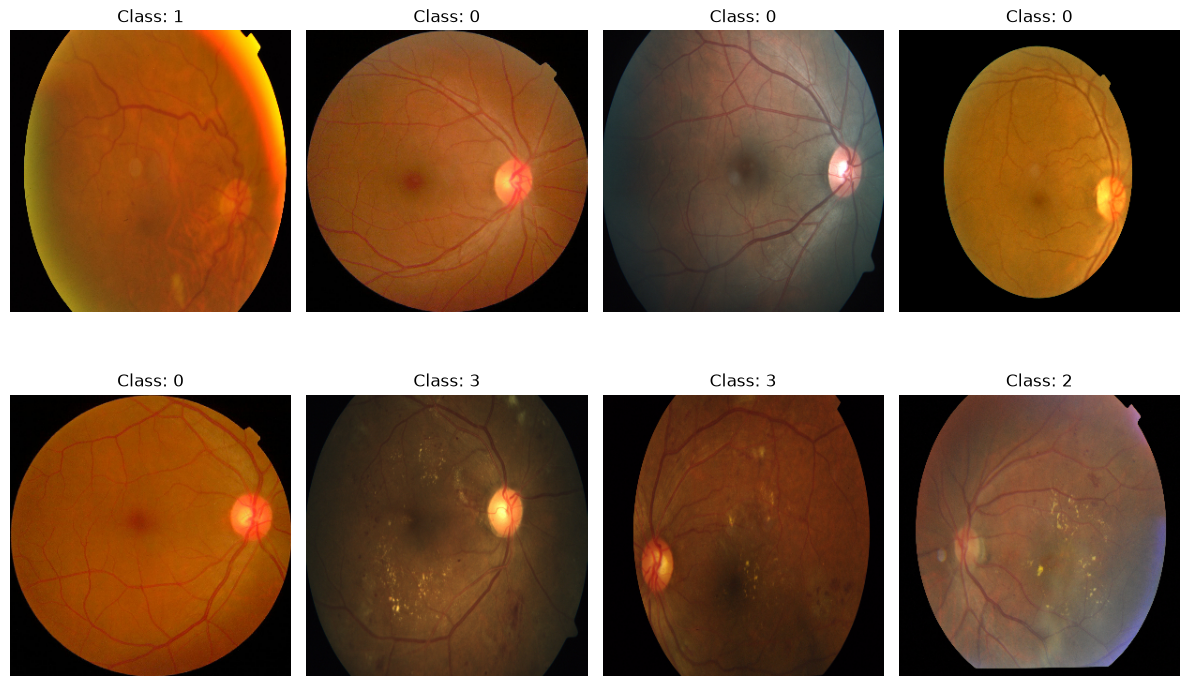

In [16]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(8, len(images))):

    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy().astype("uint8"))

    plt.title(f"Class: {labels[i].numpy()}")

    plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Data Augmentation

Apply moderate transformations to improve
model generalization.

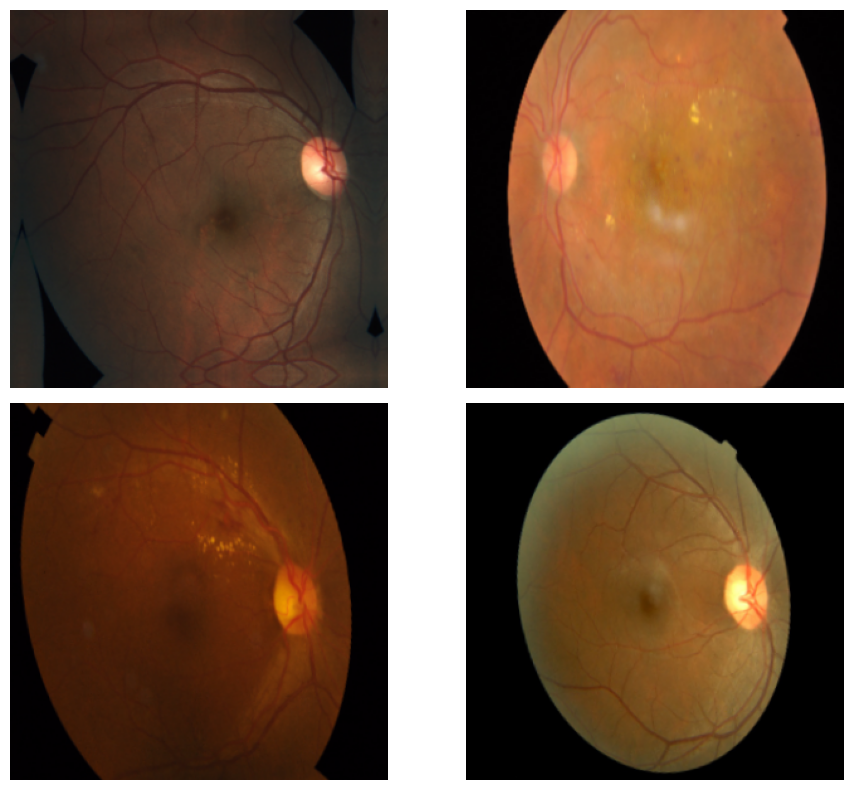

In [17]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="retinal_augmentation")

sample_images, _ = next(iter(train_ds))

augmented_images = data_augmentation(
    sample_images[:4],
    training=True
)

plt.figure(figsize=(10, 8))

for i in range(4):

    plt.subplot(2, 2, i + 1)

    plt.imshow(
        tf.cast(
            tf.clip_by_value(
                augmented_images[i], 0, 255
            ),
            tf.uint8
        )
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Class Imbalance Handling

Calculate balanced class weights to reduce
the effect of underrepresented classes.

In [18]:
classes = np.unique(train_df["diagnosis"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"]
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")

for cls, weight in class_weights.items():
    print(f"Class {cls}: {weight:.4f}")

Class weights:
Class 0: 0.4057
Class 1: 1.9791
Class 2: 0.7332
Class 3: 3.8039
Class 4: 2.4822


## 10. EfficientNetB3 Architecture

Use ImageNet pretrained EfficientNetB3
as the feature extraction backbone.

Add global average pooling, dropout,
and a five-class softmax classifier.

In [19]:
base_model = keras.applications.EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output"
)(x)

model = keras.Model(
    inputs,
    outputs,
    name="EfficientNetB3_Retinal_Classifier"
)

model.summary()

Model: "EfficientNetB3_Retinal_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ retinal_augmentation            │ (None, 300, 300, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 5)              │         7,685 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,791,220 (41.17 MB)

 Trainable params: 7,685 (30.02 KB)

 Non-trainable params: 10,783,535 (41.14 MB)

## 11. Model Compilation

Configure Adam optimizer and sparse categorical
crossentropy for five-class classification.

In [20]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully!")
print("Trainable parameters:",
      sum(np.prod(v.shape) for v in model.trainable_weights))

Model compiled successfully!
Trainable parameters: 7685


## 12. Training Callbacks

Configure checkpointing, early stopping,
and adaptive learning-rate reduction.

In [21]:
stage1_path = MODEL_DIR / "efficientnetb3_stage1_best.keras"

callbacks = [

    keras.callbacks.ModelCheckpoint(
        filepath=str(stage1_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Callbacks configured!")

Callbacks configured!


## 13. Initial Transfer Learning

Train the classification head while keeping
the pretrained EfficientNetB3 backbone frozen.

In [22]:
INITIAL_EPOCHS = 5

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5


s:\ISP\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5811 - loss: 1.2508
Epoch 1: val_loss improved from None to 0.82423, saving model to s:\ISP\notebooks\data\processed\models\efficientnetb3_stage1_best.keras

Epoch 1: finished saving model to s:\ISP\notebooks\data\processed\models\efficientnetb3_stage1_best.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 610s 2s/step - accuracy: 0.5811 - loss: 1.2508 - val_accuracy: 0.6685 - val_loss: 0.8242 - learning_rate: 0.0010
Epoch 2/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6640 - loss: 1.0531
Epoch 2: val_loss improved from 0.82423 to 0.70734, saving model to s:\ISP\notebooks\data\processed\models\efficientnetb3_stage1_best.keras

Epoch 2: finished saving model to s:\ISP\notebooks\data\processed\models\efficientnetb3_stage1_best.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 551s 2s/step - accuracy: 0.6640 - loss: 1.0531 - val_accuracy: 0.7135 - val_loss: 0.7073 - learning_rate: 0.0010
Epoch 3/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.698

In [23]:
pd.DataFrame(history1.history).to_csv(
    RESULT_DIR / "efficientnetb3_stage1_history.csv",
    index=False
)

print("Initial training completed!")

Initial training completed!


## 14. Initial Training Performance

Visualize training and validation accuracy and loss.

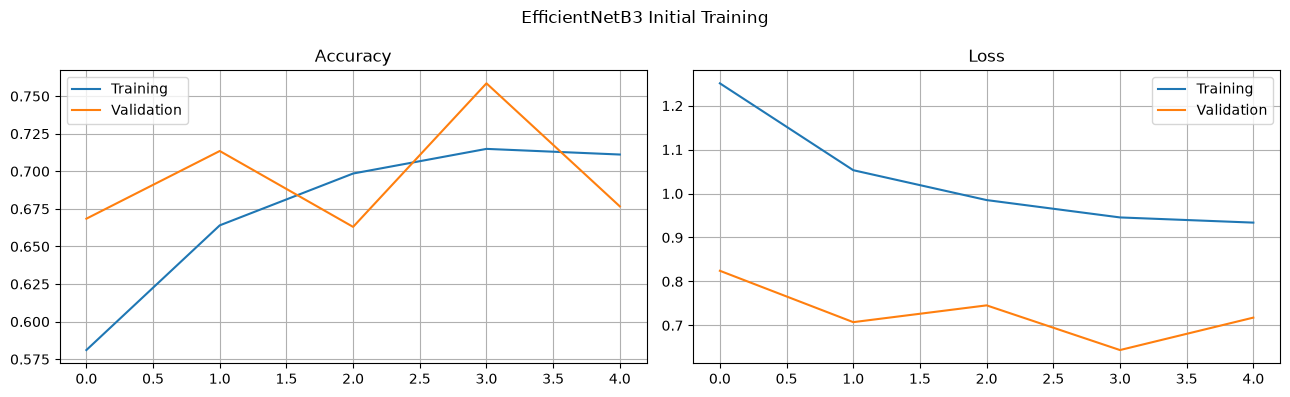

In [24]:
def plot_history(history, title):

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history.history["accuracy"], label="Training")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history.history["loss"], label="Training")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title("Loss")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(
    history1,
    "EfficientNetB3 Initial Training"
)

## 15. EfficientNetB3 Fine-Tuning

Unfreeze selected deeper layers and train them
using a low learning rate.

In [25]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total backbone layers:", len(base_model.layers))

print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))

Total backbone layers: 385
Trainable backbone layers: 23


In [26]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Fine-tuning model compiled!")

Fine-tuning model compiled!


In [27]:
finetuned_path = (
    MODEL_DIR / "efficientnetb3_finetuned_best.keras"
)

fine_callbacks = [

    keras.callbacks.ModelCheckpoint(
        filepath=str(finetuned_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [29]:
FINE_TUNE_EPOCHS = 5

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=fine_callbacks,
    verbose=1
)

Epoch 1/5


367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7231 - loss: 0.9222
Epoch 1: val_loss improved from None to 0.65519, saving model to s:\ISP\notebooks\data\processed\models\efficientnetb3_finetuned_best.keras

Epoch 1: finished saving model to s:\ISP\notebooks\data\processed\models\efficientnetb3_finetuned_best.keras
367/367 ━━━━━━━━━━━━━━━━━━━━ 591s 2s/step - accuracy: 0.7231 - loss: 0.9222 - val_accuracy: 0.7408 - val_loss: 0.6552 - learning_rate: 1.0000e-05
Epoch 2/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7395 - loss: 0.8728
Epoch 2: val_loss did not improve from 0.65519
367/367 ━━━━━━━━━━━━━━━━━━━━ 555s 2s/step - accuracy: 0.7395 - loss: 0.8728 - val_accuracy: 0.7326 - val_loss: 0.6737 - learning_rate: 1.0000e-05
Epoch 3/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7491 - loss: 0.8471
Epoch 3: val_loss did not improve from 0.65519

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
367/367 ━━━━━━━━━━━━━━━━━━━━ 576s 2s/step - 

In [30]:
pd.DataFrame(history2.history).to_csv(
    RESULT_DIR / "efficientnetb3_finetuning_history.csv",
    index=False
)

print("Fine-tuning completed!")

Fine-tuning completed!


## 16. Fine-Tuning Performance Visualization

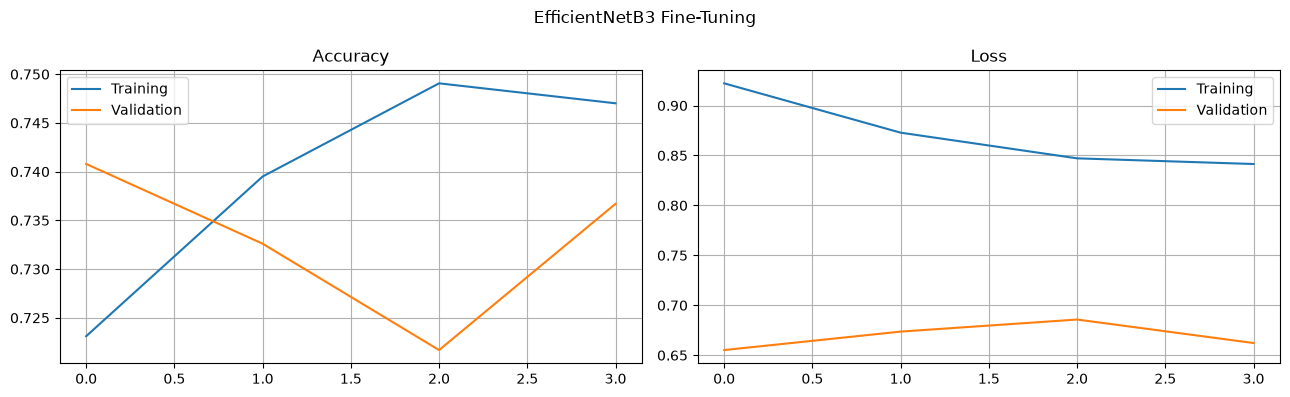

In [31]:
plot_history(
    history2,
    "EfficientNetB3 Fine-Tuning"
)

## 17. Load Best Fine-Tuned Model

In [32]:
if finetuned_path.exists():

    best_model = keras.models.load_model(
        finetuned_path
    )

    print("Best fine-tuned model loaded!")

else:

    raise FileNotFoundError(
        "Fine-tuned checkpoint was not saved."
    )

Best fine-tuned model loaded!


## 18. Model Evaluation

Evaluate the best model on the held-out validation dataset.

In [33]:
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob = best_model.predict(
    val_ds,
    verbose=1
)

y_pred = np.argmax(
    y_prob,
    axis=1
)

print("True labels:", y_true.shape)
print("Predictions:", y_pred.shape)

92/92 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step
True labels: (733,)
Predictions: (733,)


## 19. Classification Performance Metrics

Calculate accuracy, precision, recall, F1-score
and quadratic weighted kappa.

In [34]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

qwk = cohen_kappa_score(
    y_true,
    y_pred,
    weights="quadratic"
)

print("\n===== MODEL PERFORMANCE =====")

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")
print(f"QWK:       {qwk:.4f}")


===== MODEL PERFORMANCE =====
Accuracy:  74.08%
Precision: 59.80%
Recall:    60.32%
F1 Score:  57.35%
QWK:       0.8370


## 20. Class-wise Classification Report

In [35]:
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "Class 0",
        "Class 1",
        "Class 2",
        "Class 3",
        "Class 4"
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(report_df.round(4))

report_df.to_csv(
    RESULT_DIR / "efficientnetb3_classification_report.csv"
)

,precision,recall,f1-score,support
Class 0,0.9607,0.9474,0.9540,361.0000
Class 1,0.3776,0.7297,0.4977,74.0000
Class 2,0.7551,0.5550,0.6398,200.0000
Class 3,0.3448,0.5128,0.4124,39.0000
Class 4,0.5517,0.2712,0.3636,59.0000
accuracy,0.7408,0.7408,0.7408,0.7408
macro avg,0.5980,0.6032,0.5735,733.0000
weighted avg,0.7800,0.7408,0.7458,733.0000


## 21. Confusion Matrix

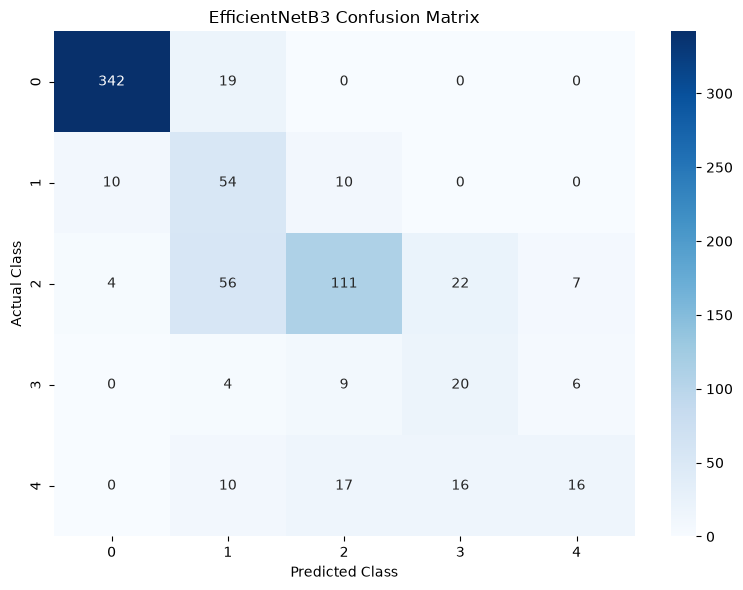

In [36]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["0", "1", "2", "3", "4"],
    yticklabels=["0", "1", "2", "3", "4"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EfficientNetB3 Confusion Matrix")

plt.tight_layout()
plt.savefig(
    RESULT_DIR / "efficientnetb3_confusion_matrix.png",
    dpi=300
)
plt.show()

## 22. Save Evaluation Results

In [37]:
results = {
    "Model": "EfficientNetB3",
    "Accuracy": float(accuracy),
    "Macro Precision": float(precision),
    "Macro Recall": float(recall),
    "Macro F1": float(f1),
    "Quadratic Weighted Kappa": float(qwk)
}

with open(
    RESULT_DIR / "efficientnetb3_validation_results.json",
    "w"
) as file:

    json.dump(results, file, indent=4)

print(json.dumps(results, indent=4))

{
    "Model": "EfficientNetB3",
    "Accuracy": 0.7407912687585266,
    "Macro Precision": 0.5979900599760013,
    "Macro Recall": 0.6032210208561681,
    "Macro F1": 0.5734895396077204,
    "Quadratic Weighted Kappa": 0.8370101702329311
}


## 23. Model Efficiency Analysis

Measure model size, trainable parameters,
and average inference latency.

In [38]:
import time

# Warm-up
sample_batch = next(iter(val_ds))[0][:1]

for _ in range(5):
    _ = best_model(sample_batch, training=False)

# Measure inference time
runs = 30
start = time.perf_counter()

for _ in range(runs):
    _ = best_model(sample_batch, training=False)

end = time.perf_counter()

avg_latency = (end - start) / runs

model_size = finetuned_path.stat().st_size / (1024 * 1024)

total_params = best_model.count_params()

print("===== EFFICIENCY RESULTS =====")
print("Total parameters:", f"{total_params:,}")
print("Model size:", f"{model_size:.2f} MB")
print("Average latency:", f"{avg_latency * 1000:.2f} ms")

===== EFFICIENCY RESULTS =====
Total parameters: 10,791,220
Model size: 69.51 MB
Average latency: 972.46 ms


## 24. Save Final EfficientNetB3 Model

In [39]:
final_model_path = (
    MODEL_DIR / "efficientnetb3_final.keras"
)

best_model.save(final_model_path)

print("Final model saved successfully!")
print("Location:", final_model_path)

Final model saved successfully!
Location: s:\ISP\notebooks\data\processed\models\efficientnetb3_final.keras


## 25. Save Validation Predictions

In [40]:
prediction_df = pd.DataFrame({
    "id_code": val_df["id_code"],
    "actual_class": y_true,
    "predicted_class": y_pred,
    "confidence": np.max(y_prob, axis=1)
})

prediction_df.to_csv(
    RESULT_DIR / "efficientnetb3_predictions.csv",
    index=False
)

display(prediction_df.head(10))

print("Predictions saved successfully!")

,id_code,actual_class,predicted_class,confidence
0,6fe67fd7f5d1,0,0,0.955520
1,ef8c39eb9157,0,0,0.982701
2,61bbc11fe503,4,3,0.317665
3,60edda7b4871,0,0,0.893615
4,d30d079e6f9a,0,0,0.976373
5,d57d1be1bbd1,0,0,0.791869
6,44855f666225,2,3,0.497758
7,7b29e3783919,3,3,0.657535
8,1594ca6c30d3,2,3,0.530458
9,eba3acc42197,1,1,0.743404


Predictions saved successfully!


## 26. Final Conclusion

EfficientNetB3 was implemented using ImageNet
transfer learning and fine-tuning.

The model was evaluated using:

1. Accuracy
2. Macro Precision
3. Macro Recall
4. Macro F1-score
5. Quadratic Weighted Kappa
6. Confusion Matrix
7. Model Size
8. Inference Latency

The best-performing checkpoint and evaluation
results were saved for future comparison.

The trained model will serve as the EfficientNetB3
baseline for the Retinopathy Detection System.

In [41]:
print("=" * 50)
print("RETINOPATHY DETECTION SYSTEM")
print("EFFICIENTNETB3 MODEL SUMMARY")
print("=" * 50)

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")
print(f"QWK:       {qwk:.4f}")

print("\nModel size:", f"{model_size:.2f} MB")
print("Inference:", f"{avg_latency * 1000:.2f} ms")

print("\nModel location:", final_model_path)
print("Results location:", RESULT_DIR)

print("\nMODEL DEVELOPMENT COMPLETED")

RETINOPATHY DETECTION SYSTEM
EFFICIENTNETB3 MODEL SUMMARY
Accuracy:  74.08%
Precision: 59.80%
Recall:    60.32%
F1 Score:  57.35%
QWK:       0.8370

Model size: 69.51 MB
Inference: 972.46 ms

Model location: s:\ISP\notebooks\data\processed\models\efficientnetb3_final.keras
Results location: s:\ISP\notebooks\data\processed\results

MODEL DEVELOPMENT COMPLETED


In [42]:
PROJECT_ROOT = Path.cwd().parent

MODEL_DIR = PROJECT_ROOT / "data" / "processed" / "models"
RESULT_DIR = PROJECT_ROOT / "data" / "processed" / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

In [43]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

MODEL_DIR = PROJECT_ROOT / "data" / "processed" / "models"
RESULT_DIR = PROJECT_ROOT / "data" / "processed" / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULT_DIR)

Project root: s:\ISP
Model directory: s:\ISP\data\processed\models
Results directory: s:\ISP\data\processed\results


## 27. Save Final Model in Project Directory

The trained EfficientNetB3 model is saved in the
centralized project model directory for reuse.

In [44]:
final_model_path = MODEL_DIR / "efficientnetb3_final.keras"

best_model.save(final_model_path)

print("Model saved:", final_model_path)
print("File exists:", final_model_path.exists())
print("Model size (MB):", round(
    final_model_path.stat().st_size / (1024 * 1024), 2
))

Model saved: s:\ISP\data\processed\models\efficientnetb3_final.keras
File exists: True
Model size (MB): 69.5


## 28. Detailed Classification Report

Evaluate class-wise precision, recall, F1-score,
and support using validation predictions.

In [45]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "Class 0",
        "Class 1",
        "Class 2",
        "Class 3",
        "Class 4"
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

report_df.to_csv(
    RESULT_DIR / "efficientnetb3_classification_report.csv"
)

print("Classification report saved!")

,precision,recall,f1-score,support
Class 0,0.9607,0.9474,0.9540,361.0000
Class 1,0.3776,0.7297,0.4977,74.0000
Class 2,0.7551,0.5550,0.6398,200.0000
Class 3,0.3448,0.5128,0.4124,39.0000
Class 4,0.5517,0.2712,0.3636,59.0000
accuracy,0.7408,0.7408,0.7408,0.7408
macro avg,0.5980,0.6032,0.5735,733.0000
weighted avg,0.7800,0.7408,0.7458,733.0000


Classification report saved!


## 29. Confusion Matrix Analysis

Visualize the classification errors across
the five retinal image categories.

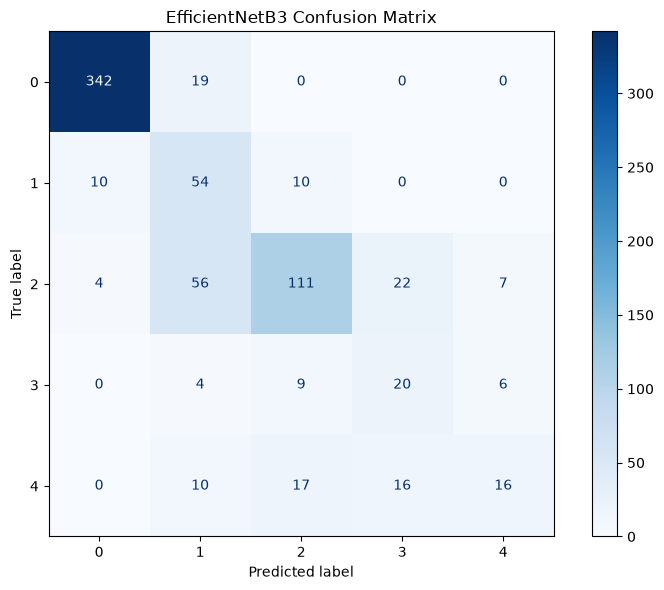

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("EfficientNetB3 Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "efficientnetb3_confusion_matrix.png",
    dpi=300
)

plt.show()

## 30. Incorrect Prediction Analysis

Identify incorrectly classified validation images
to understand model limitations.

In [47]:
error_df = pd.DataFrame({
    "id_code": val_df["id_code"].values,
    "actual": y_true,
    "predicted": y_pred,
    "confidence": np.max(y_prob, axis=1)
})

error_df = error_df[
    error_df["actual"] != error_df["predicted"]
]

display(error_df.head(20))

error_df.to_csv(
    RESULT_DIR / "efficientnetb3_errors.csv",
    index=False
)

print("Total incorrect predictions:", len(error_df))

,id_code,actual,predicted,confidence
2,61bbc11fe503,4,3,0.317665
6,44855f666225,2,3,0.497758
8,1594ca6c30d3,2,3,0.530458
13,259d30f693b6,1,0,0.788347
21,82ac8463fadd,1,0,0.923338
31,7a6e384a0846,3,1,0.564659
32,51131b48f9d4,1,2,0.460047
34,282bc792d23a,2,1,0.542076
40,034cb07a550f,4,3,0.350681
44,c0a0828e01b4,3,2,0.589767


Total incorrect predictions: 190


## 31. Model and Results Verification

Verify that the trained model and evaluation
artifacts are available in the project directories.

In [48]:
print("MODEL DIRECTORY")
print("=" * 40)

for file in MODEL_DIR.iterdir():
    if file.is_file():
        print(file.name)

print("\nRESULT DIRECTORY")
print("=" * 40)

for file in RESULT_DIR.iterdir():
    if file.is_file():
        print(file.name)

MODEL DIRECTORY
efficientnetb3_final.keras

RESULT DIRECTORY
efficientnetb3_classification_report.csv
efficientnetb3_confusion_matrix.png
efficientnetb3_errors.csv


## 32. Final Conclusion

EfficientNetB3 was implemented using transfer learning
and fine-tuning with ImageNet pretrained weights.

The model was evaluated using:

1. Accuracy
2. Macro Precision
3. Macro Recall
4. Macro F1-score
5. Quadratic Weighted Kappa
6. Confusion Matrix
7. Model Size
8. Inference Latency

The model achieved an initial validation accuracy
of 74.08%.

Further improvements will be investigated through
class-wise error analysis, model optimization,
and comparison with MobileNetV2.

The trained EfficientNetB3 model will serve as
the baseline for the Retinopathy Detection System.

In [49]:
from pathlib import Path

for f in RESULT_DIR.glob("*split*.csv"):
    print(f.name)

In [50]:
print("train_df exists:", "train_df" in globals())
print("val_df exists:", "val_df" in globals())

train_df exists: True
val_df exists: True


In [51]:
# Save the original EfficientNetB3 train-validation split

train_df[["id_code", "diagnosis"]].to_csv(
    RESULT_DIR / "efficientnetb3_train_split.csv",
    index=False
)

val_df[["id_code", "diagnosis"]].to_csv(
    RESULT_DIR / "efficientnetb3_validation_split.csv",
    index=False
)

print("Original dataset splits saved successfully!")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Original dataset splits saved successfully!
Training images: 2929
Validation images: 733


In [52]:
print("Saved split files:")

for f in RESULT_DIR.glob("*split*.csv"):
    print(f.name, "|", f.stat().st_size, "bytes")

Saved split files:
efficientnetb3_train_split.csv | 46883 bytes
efficientnetb3_validation_split.csv | 11747 bytes
